# 03: Kilitli tahminlerle bağımsız test değerlendirmesi
Bu notebook **yalnızca** `results/test_predictions_locked.csv` ayrı bir commit ile kaydedildikten sonra çalıştırılır.
Model, eşik (0.50) ve ön işleme kuralı bu aşamada değiştirilmez. Test etiketleri burada ilk kez okunur.
Ana sonuç önceden ilan edilen birincil seed'dir; en yüksek test skorlu seed seçilmez.

In [1]:
# --- Ortam kurulumu (Colab'da repo klonlanır; yerelde repo kökünden çalıştırın) ---
import os, sys, platform
REPO_URL = "https://github.com/ibrahimalpsoy/ysa-midterm-bank-mlp.git"
if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists("ysa-midterm-bank-mlp"):
        os.system(f"git clone {REPO_URL}")
    os.chdir("ysa-midterm-bank-mlp")
    os.system("pip install -q -r requirements.txt")
sys.path.insert(0, os.path.abspath("."))

import json, warnings
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from src import config as C
C.ensure_dirs(); C.set_global_seeds()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9})
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)
print("BASE_SEED =", C.BASE_SEED, "| türetilmiş seedler:", C.SEEDS)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5
BASE_SEED = 31066 | türetilmiş seedler: {'python': 31066, 'numpy': 31067, 'torch': 31068, 'split': 31069, 'outer_cv': 31070, 'inner_cv': 31071, 'random_search': 31072, 'early_stop_split': 31073, 'bootstrap': 31074}


In [2]:
import subprocess
from sklearn.metrics import (roc_curve, precision_recall_curve, confusion_matrix, brier_score_loss)
from sklearn.calibration import calibration_curve
from src import data as D
from src.metrics import compute_metrics, bootstrap_ci, METRIC_ORDER

# Kilit kontrolü: tahmin dosyası git'te commit edilmiş ve sonradan değişmemiş olmalı
def git(*a):
    try: return subprocess.run(["git", *a], capture_output=True, text=True, check=True).stdout.strip()
    except Exception as e: return f"(git yok: {e})"
lock_commit = git("log", "-1", "--format=%H %ad %s", "--", "results/test_predictions_locked.csv")
dirty = git("status", "--porcelain", "results/test_predictions_locked.csv")  # tahminler deterministik; yeniden çalıştırmada birebir aynı kalmalı
print("Kilit commit'i:", lock_commit); print("Kilitten sonra değişiklik:", dirty or "yok")
assert lock_commit and not lock_commit.startswith("(git"), "Önce kilitli tahminleri commit edin!"
if dirty:
    print("UYARI: test_predictions_locked.csv commit edilmiş sürümden farklı. Farklı kütüphane sürümleri küçük sayısal farklar üretebilir; "
          "raporlanan sonuçlar commit edilmiş kilitli dosyaya aittir.")

Kilit commit'i: d463f752a16fa0ce3babebf05a720622df42fea3 Sun Nov 15 12:53:01 2026 +0300 ödev teslim
Kilitten sonra değişiklik: yok


## 1. Kilitli tahminler ve test etiketleri (etiketler burada ilk kez okunur)

In [3]:
locked = pd.read_csv(C.RESULTS_DIR / "test_predictions_locked.csv")
manifest = json.load(open(C.RESULTS_DIR / "test_predictions_locked_manifest.json"))
final = json.load(open(C.RESULTS_DIR / "final_hyperparameters.json"))
df = D.load_raw(); D.validate_raw(df)
y_test = (df.loc[locked["original_row_index"], "y"] == "yes").astype(int).to_numpy()
split = pd.read_csv(C.RESULTS_DIR / "dataset_split.csv").set_index("original_row_index")
assert (split.loc[locked["original_row_index"], "subset"] == "test").all()
PRIMARY = manifest["primary_seed"]; SEEDS3 = final["all_torch_seeds"]
print(f"Test n={len(y_test)}, pozitif={y_test.sum()} (%{100*y_test.mean():.2f}) | birincil seed={PRIMARY} | nihai aday={final['selected_code']} ({final['selected_method']})")

Test n=824, pozitif=90 (%10.92) | birincil seed=31068 | nihai aday=R5 (random)


## 2. Test metrikleri (eşik = 0.50), MLP (birincil seed), LogisticRegression, Dummy

In [4]:
models = {f"MLP {final['selected_code']} (seed {PRIMARY})": f"mlp_proba_seed{PRIMARY}",
          "LogisticRegression": "logreg_proba", "Dummy(prior)": "dummy_proba"}
tm = pd.DataFrame({name: compute_metrics(y_test, locked[col]) for name, col in models.items()}).T
tm["Brier"] = [brier_score_loss(y_test, locked[c]) for c in models.values()]
tm.index.name = "model"; tm.to_csv(C.RESULTS_DIR / "test_metrics.csv")
display(tm[METRIC_ORDER + ["PR_AUC_trapezoid", "Brier", "TP", "FP", "TN", "FN"]].round(4))

,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,PR_AUC_trapezoid,Brier,TP,FP,TN,FN
model,,,,,,,,,,,,,,
MLP R5 (seed 31068),0.4399,0.7837,0.9017,0.6452,0.2222,0.985,0.3306,0.6036,0.4350,0.0781,20.0,11.0,723.0,70.0
LogisticRegression,0.4372,0.7930,0.9005,0.6333,0.2111,0.985,0.3167,0.5981,0.4294,0.0776,19.0,11.0,723.0,71.0
Dummy(prior),0.1092,0.5000,0.8908,0.0000,0.0000,1.000,0.0000,0.5000,0.5546,0.0973,0.0,0.0,734.0,90.0


## 3. Bootstrap %95 yüzdelik güven aralıkları (1.000 tekrar, her örneklemde iki sınıf kontrolü)

In [5]:
ci = []
for name, col in list(models.items())[:2]:
    b = bootstrap_ci(y_test, locked[col].to_numpy()); b.insert(0, "model", name); ci.append(b)
ci = pd.concat(ci, ignore_index=True); ci.to_csv(C.RESULTS_DIR / "test_bootstrap_ci.csv", index=False)
ci["CI_95"] = [f"[{l:.3f}, {h:.3f}]" for l, h in zip(ci.ci_low, ci.ci_high)]
display(ci[["model", "metric", "point", "CI_95", "n_boot", "single_class_redraws"]].round(4))
# MLP - LR farkı için eşleştirilmiş bootstrap (aynı yeniden örneklem indeksleri)
rng = np.random.default_rng(C.SEEDS["bootstrap"]); pm, pl = locked[models[list(models)[0]]].to_numpy(), locked["logreg_proba"].to_numpy()
from sklearn.metrics import average_precision_score, roc_auc_score
d_ap, d_auc = [], []
while len(d_ap) < C.N_BOOTSTRAP:
    ix = rng.integers(0, len(y_test), len(y_test))
    if y_test[ix].min() == y_test[ix].max(): continue
    d_ap.append(average_precision_score(y_test[ix], pm[ix]) - average_precision_score(y_test[ix], pl[ix]))
    d_auc.append(roc_auc_score(y_test[ix], pm[ix]) - roc_auc_score(y_test[ix], pl[ix]))
diff = pd.DataFrame({"metric": ["AP (MLP-LR)", "ROC_AUC (MLP-LR)"],
                     "point": [tm.iloc[0]["AP"] - tm.loc["LogisticRegression", "AP"], tm.iloc[0]["ROC_AUC"] - tm.loc["LogisticRegression", "ROC_AUC"]],
                     "ci_low": [np.percentile(d_ap, 2.5), np.percentile(d_auc, 2.5)], "ci_high": [np.percentile(d_ap, 97.5), np.percentile(d_auc, 97.5)]})
diff.to_csv(C.RESULTS_DIR / "test_bootstrap_diff_mlp_vs_lr.csv", index=False); display(diff.round(4))

,model,metric,point,CI_95,n_boot,single_class_redraws
0,MLP R5 (seed 31068),ROC_AUC,0.7837,"[0.727, 0.843]",1000,0
1,MLP R5 (seed 31068),AP,0.4399,"[0.336, 0.561]",1000,0
2,MLP R5 (seed 31068),F1,0.3306,"[0.213, 0.433]",1000,0
3,LogisticRegression,ROC_AUC,0.7930,"[0.736, 0.850]",1000,0
4,LogisticRegression,AP,0.4372,"[0.339, 0.563]",1000,0
5,LogisticRegression,F1,0.3167,"[0.210, 0.428]",1000,0


,metric,point,ci_low,ci_high
0,AP (MLP-LR),0.0027,-0.0204,0.0225
1,ROC_AUC (MLP-LR),-0.0093,-0.0317,0.0124


## 4. Seed kararlılığı: üç önceden ilan edilmiş ağırlık seed'i (betimsel Mean ± SD)

In [6]:
ss = pd.DataFrame({s: compute_metrics(y_test, locked[f"mlp_proba_seed{s}"]) for s in SEEDS3}).T
ss.index.name = "torch_seed"; ss["primary"] = [s == PRIMARY for s in ss.index]
ss["best_epoch"] = [final["per_seed"][str(s)]["best_epoch"] for s in ss.index]
summ = pd.DataFrame({"mean": ss[METRIC_ORDER].mean(), "sd": ss[METRIC_ORDER].std(ddof=1)}).T
out = pd.concat([ss[METRIC_ORDER + ["best_epoch", "primary"]], summ]); out.to_csv(C.RESULTS_DIR / "seed_stability_results.csv")
display(out.round(4))

,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy,best_epoch,primary
31068,0.4399,0.7837,0.9017,0.6452,0.2222,0.9850,0.3306,0.6036,20.0,True
31166,0.4281,0.7857,0.9017,0.6364,0.2333,0.9837,0.3415,0.6085,23.0,False
31266,0.4290,0.7804,0.9017,0.6552,0.2111,0.9864,0.3193,0.5987,19.0,False
mean,0.4323,0.7833,0.9017,0.6456,0.2222,0.9850,0.3305,0.6036,NaN,NaN
sd,0.0066,0.0027,0.0000,0.0094,0.0111,0.0014,0.0111,0.0049,NaN,NaN


## 5. Confusion matrix (Şekil 6) ve ROC / Precision-Recall eğrileri (Şekil 7)

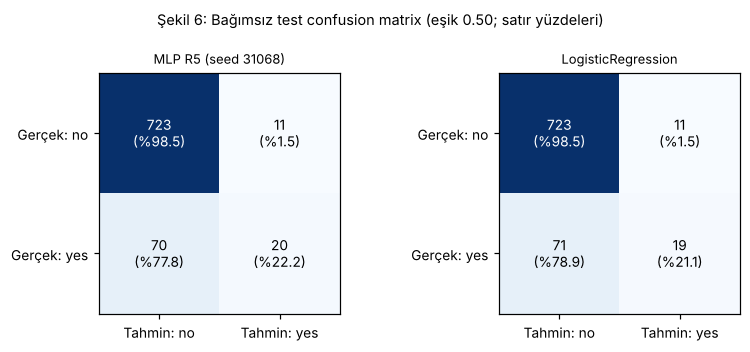

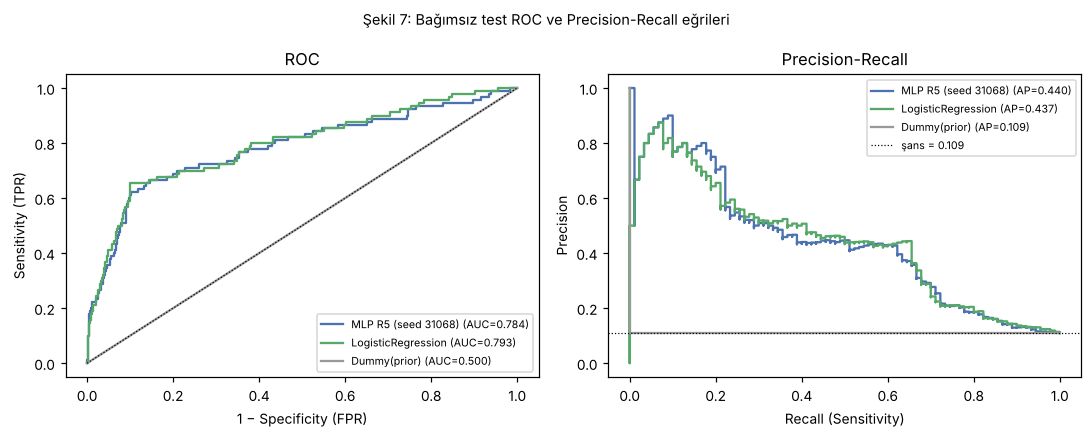

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
for ax, (name, col) in zip(axes, list(models.items())[:2]):
    cm = confusion_matrix(y_test, (locked[col] >= C.THRESHOLD).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n(%{100 * cm[i, j] / cm[i].sum():.1f})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Tahmin: no", "Tahmin: yes"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Gerçek: no", "Gerçek: yes"])
    ax.set_title(name, fontsize=8.5)
fig.suptitle("Şekil 6: Bağımsız test confusion matrix (eşik 0.50; satır yüzdeleri)", fontsize=9.5); fig.tight_layout()
fig.savefig(C.FIG_DIR / "fig06_confusion_matrices.png"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ["#4c72b0", "#55a868", "#999999"]
for (name, col), c in zip(models.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, locked[col]); axes[0].plot(fpr, tpr, color=c, label=f"{name} (AUC={tm.loc[name, 'ROC_AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, locked[col]); axes[1].step(rc, pr, where="post", color=c, label=f"{name} (AP={tm.loc[name, 'AP']:.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=.8); axes[0].set_xlabel("1 − Specificity (FPR)"); axes[0].set_ylabel("Sensitivity (TPR)"); axes[0].set_title("ROC")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=.8, label=f"şans = {y_test.mean():.3f}")
axes[1].set_xlabel("Recall (Sensitivity)"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall")
for ax in axes: ax.legend(fontsize=7)
fig.suptitle("Şekil 7: Bağımsız test ROC ve Precision-Recall eğrileri", fontsize=9.5); fig.tight_layout()
fig.savefig(C.FIG_DIR / "fig07_roc_pr_curves.png"); plt.show()

## 6. Başarısızlık analizi: False Positive / False Negative örnekleri (betimsel)

In [8]:
pcol = models[list(models)[0]]
p = locked[pcol].to_numpy(); pred = (p >= C.THRESHOLD).astype(int)
Xt = df.loc[locked["original_row_index"]].drop(columns=["y"] + D.DROP_COLS).reset_index(drop=True)
grp = np.select([(y_test == 1) & (pred == 1), (y_test == 0) & (pred == 1), (y_test == 1) & (pred == 0), (y_test == 0) & (pred == 0)], ["TP", "FP", "FN", "TN"], default="?")
Xt["outcome"] = grp; Xt["proba"] = p; Xt["prev_contacted"] = (Xt["pdays"] != 999).astype(int)
cnt = Xt["outcome"].value_counts().reindex(["TP", "FP", "FN", "TN"]).rename("n").to_frame()
cnt["share_of_true_class_%"] = [100 * cnt.loc["TP", "n"] / y_test.sum(), 100 * cnt.loc["FP", "n"] / (1 - y_test).sum(),
                                 100 * cnt.loc["FN", "n"] / y_test.sum(), 100 * cnt.loc["TN", "n"] / (1 - y_test).sum()]
display(cnt.round(2))
prof = Xt.groupby("outcome").agg(n=("proba", "size"), proba_median=("proba", "median"), euribor3m_median=("euribor3m", "median"),
                                 nr_employed_median=("nr.employed", "median"), prev_contacted_rate=("prev_contacted", "mean"),
                                 poutcome_success_rate=("poutcome", lambda s: (s == "success").mean()),
                                 cellular_rate=("contact", lambda s: (s == "cellular").mean()), campaign_median=("campaign", "median"),
                                 age_median=("age", "median")).reindex(["TP", "FP", "FN", "TN"])
prof.to_csv(C.RESULTS_DIR / "test_error_analysis.csv"); display(prof.round(3))
fn_p = Xt.query("outcome=='FN'")["proba"]
print(f"FN olasılık dağılımı: medyan={fn_p.median():.3f}, %75={fn_p.quantile(.75):.3f}, 0.30 üstü={int((fn_p > .3).sum())}/{len(fn_p)}")

,n,share_of_true_class_%
outcome,,
TP,20,22.22
FP,11,1.50
FN,70,77.78
TN,723,98.50


,n,proba_median,euribor3m_median,nr_employed_median,prev_contacted_rate,poutcome_success_rate,cellular_rate,campaign_median,age_median
outcome,,,,,,,,,
TP,20,0.739,0.780,4991.6,0.950,0.900,0.900,1.0,45.5
FP,11,0.590,0.742,5008.7,0.636,0.545,0.818,1.0,55.0
FN,70,0.153,1.360,5099.1,0.029,0.029,0.886,2.0,42.0
TN,723,0.050,4.857,5195.8,0.006,0.004,0.604,2.0,38.0


FN olasılık dağılımı: medyan=0.153, %75=0.233, 0.30 üstü=13/70


## 7. Ek (isteğe bağlı) analizler, test verisiyle hiçbir şey optimize edilmez
Kalibrasyon eğrisi, Brier skoru ve eşik duyarlılığı **yalnızca betimsel** olarak verilir. Nihai eşik 0.50 olarak kalır.

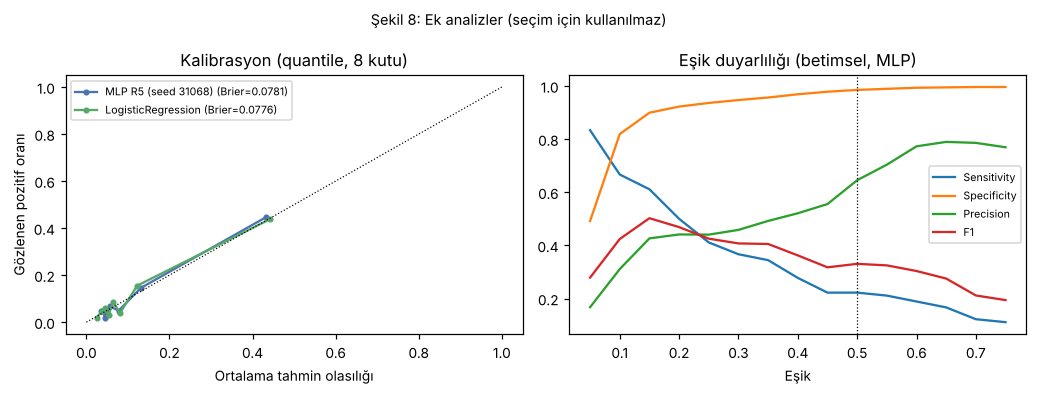

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for (name, col), c in zip(list(models.items())[:2], colors):
    fp_, mp_ = calibration_curve(y_test, locked[col], n_bins=8, strategy="quantile")
    axes[0].plot(mp_, fp_, "o-", color=c, ms=3, label=f"{name} (Brier={tm.loc[name, 'Brier']:.4f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=.8); axes[0].set_xlabel("Ortalama tahmin olasılığı"); axes[0].set_ylabel("Gözlenen pozitif oranı")
axes[0].set_title("Kalibrasyon (quantile, 8 kutu)"); axes[0].legend(fontsize=7)
ths = np.round(np.arange(.05, .8, .05), 2); rows = []
for t in ths:
    m = compute_metrics(y_test, locked[pcol], threshold=t); rows.append({"threshold": t, **{k: m[k] for k in ["Sensitivity", "Specificity", "Precision", "F1", "Balanced_Accuracy"]}})
thr = pd.DataFrame(rows); thr.to_csv(C.RESULTS_DIR / "test_threshold_sensitivity_descriptive.csv", index=False)
for k in ["Sensitivity", "Specificity", "Precision", "F1"]: axes[1].plot(thr.threshold, thr[k], label=k)
axes[1].axvline(C.THRESHOLD, color="k", ls=":", lw=.8); axes[1].set_xlabel("Eşik"); axes[1].set_title("Eşik duyarlılığı (betimsel, MLP)"); axes[1].legend(fontsize=7)
fig.suptitle("Şekil 8: Ek analizler (seçim için kullanılmaz)", fontsize=9.5); fig.tight_layout()
fig.savefig(C.FIG_DIR / "fig08_calibration_threshold.png"); plt.show()

## 8. Üç değerlendirme düzeyinin yan yana gösterimi

In [10]:
outer = pd.read_csv(C.RESULTS_DIR / "outer_cv_results.csv")
fd = pd.read_csv(C.RESULTS_DIR / ("manual_search_results.csv" if final["selected_method"] == "manual" else "random_search_results.csv")).query("stage=='full_dev'").set_index("code")
mname = f"MLP-{final['selected_method']}"
ap_ci = ci[(ci.metric == "AP") & (ci.model == list(models)[0])].iloc[0]
lvl = pd.DataFrame([
    {"düzey": "Dış CV (seçilen yöntem prosedürü, Mean ± SD, n=3)", "AP": f"{outer.query('model==@mname').AP.mean():.4f} ± {outer.query('model==@mname').AP.std(ddof=1):.4f}"},
    {"düzey": f"Tam development iç CV ({final['selected_code']}, seçim skoru, iyimser yanlı)", "AP": f"{fd.loc[final['selected_code'], 'AP_mean']:.4f} ± {fd.loc[final['selected_code'], 'AP_sd']:.4f}"},
    {"düzey": f"Bağımsız test (birincil seed {PRIMARY})", "AP": f"{tm.iloc[0]['AP']:.4f}  [95% CI {ap_ci.ci_low:.3f}, {ap_ci.ci_high:.3f}]"},
    {"düzey": "Bağımsız test (3 seed, Mean ± SD)", "AP": f"{ss['AP'].mean():.4f} ± {ss['AP'].std(ddof=1):.4f}"},
])
lvl.to_csv(C.RESULTS_DIR / "summary_three_levels.csv", index=False); display(lvl)

,düzey,AP
0,"Dış CV (seçilen yöntem prosedürü, Mean ± SD, n=3)",0.4050 ± 0.0437
1,"Tam development iç CV (R5, seçim skoru, iyimse...",0.4370 ± 0.0256
2,Bağımsız test (birincil seed 31068),"0.4399 [95% CI 0.336, 0.561]"
3,"Bağımsız test (3 seed, Mean ± SD)",0.4323 ± 0.0066
